# Лабораторная 1. Полутоновые изображения и примитивный датчик движения

**Задание**

1. Загрузка изображения.
   Преобразование к полутоновому изображению двумя способами:
   * `Gray = 0.3 * R + 0.59 * G + 0.11 * B`
   * `Gray = (R + G + B) / 3`

   Получить разность этих полутоновых изображений.

2. Взять фрагмент видео и покадрово обрабатывать:
   * преобразовывать кадр к полутоновому;
   * получать разность между соседними кадрами — примитивнейший датчик движения.


In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from pathlib import Path

BASE_DIR = next((p for p in (Path("assets"), Path("lab1/assets")) if p.is_dir()), Path("assets"))
OUT_DIR = BASE_DIR.resolve().parent / "outputs"
OUT_DIR.mkdir(exist_ok=True)


## 1. Загрузка изображения


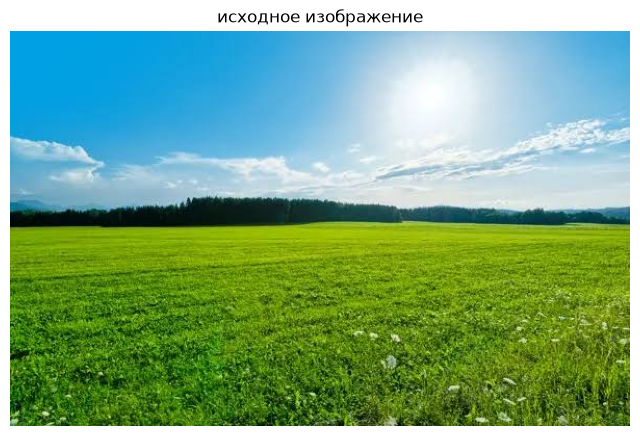

In [50]:
image_path = str(BASE_DIR / "image.jpg")

image = cv2.imread(image_path, cv2.IMREAD_COLOR_RGB)
if image is None:
    raise FileNotFoundError(image_path)

h, w = image.shape[:2]

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title("исходное изображение")
plt.axis("off")
plt.show()


## 2. Два способа перевода в полутон

* `gray_weighted = 0.3 * R + 0.59 * G + 0.11 * B`
* `gray_mean = (R + G + B) / 3`


In [51]:
gray_weighted = np.zeros((h, w), dtype=np.uint8)
gray_mean = np.zeros((h, w), dtype=np.uint8)

for i in range(h):
    for j in range(w):
        r = int(image[i, j, 0])
        g = int(image[i, j, 1])
        b = int(image[i, j, 2])

        gray_weighted[i, j] = np.clip(round(0.3 * r + 0.59 * g + 0.11 * b), 0, 255)
        gray_mean[i, j] = np.clip(round((r + g + b) / 3), 0, 255)


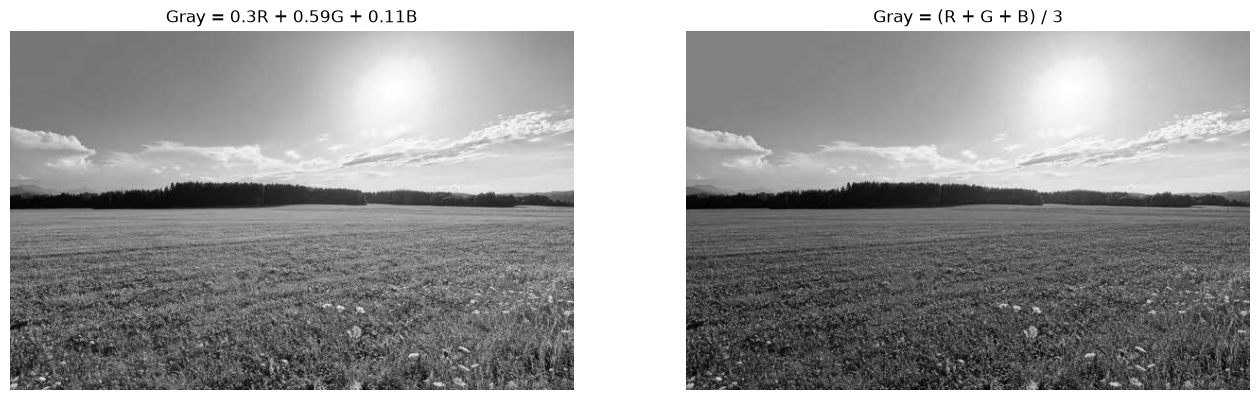

In [52]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.imshow(gray_weighted, "gray", vmin=0, vmax=255)
plt.title("Gray = 0.3R + 0.59G + 0.11B")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_mean, "gray", vmin=0, vmax=255)
plt.title("Gray = (R + G + B) / 3")
plt.axis("off")

plt.show()


## 3. Разность полутоновых изображений


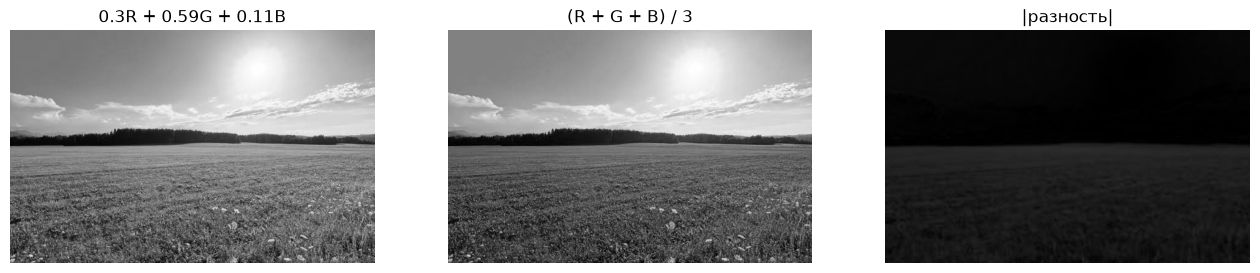

In [53]:
diff = cv2.absdiff(gray_weighted, gray_mean)

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_weighted, "gray", vmin=0, vmax=255)
plt.title("0.3R + 0.59G + 0.11B")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray_mean, "gray", vmin=0, vmax=255)
plt.title("(R + G + B) / 3")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(diff, "gray", vmin=0, vmax=255)
plt.title("|разность|")
plt.axis("off")

plt.show()


In [54]:
cv2.imwrite(str(OUT_DIR / "gray_weighted.png"), gray_weighted)
cv2.imwrite(str(OUT_DIR / "gray_mean.png"), gray_mean)
cv2.imwrite(str(OUT_DIR / "diff_abs.png"), diff)


True

## 4. Фрагмент видео: полутон и разность соседних кадров

Кадр переводим в полутон, затем берём разность с предыдущим кадром — это и есть
примитивнейший датчик движения.


In [59]:
video_path = str(BASE_DIR / "video.mp4")
gray_video_path = str(OUT_DIR / "video_grayscale.mp4")
diff_video_path = str(OUT_DIR / "video_diff.mp4")

fragment_sec = 5.0  # длина обрабатываемого фрагмента

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise FileNotFoundError(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frames_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

if fps <= 0:  # некоторые контейнеры не отдают fps
    fps = 25.0

fragment_frames = max(int(fragment_sec * fps), 0)
if frames_count > 0:
    fragment_frames = min(fragment_frames, frames_count)

print(f"Video    : {w}x{h}, fps: {fps:.1f}, frames: {frames_count}")
print(f"Fragment : {fragment_frames} frames ({fragment_frames / fps:.2f} sec)")


Video    : 480x360, fps: 10.0, frames: 795
Fragment : 50 frames (5.00 sec)


In [61]:
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise FileNotFoundError(video_path)

video_codec = cv2.VideoWriter_fourcc(*"mp4v")
gray_writer = cv2.VideoWriter(gray_video_path, video_codec, fps, (w, h))
diff_writer = cv2.VideoWriter(diff_video_path, video_codec, fps, (w, h))

samples = []     # несколько первых кадров для показа
prev_gray = None
n_frame = 0

try:
    while n_frame < fragment_frames:
        ret, frame = cap.read()
        if not ret:
            break

        # 1) преобразование кадра к полутоновому
        gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        gray_writer.write(cv2.cvtColor(gray_frame, cv2.COLOR_GRAY2BGR))

        # 2) разность между соседними кадрами
        if prev_gray is None:
            diff_frame = np.zeros_like(gray_frame)
        else:
            diff_frame = cv2.absdiff(gray_frame, prev_gray)
        prev_gray = gray_frame

        diff_writer.write(cv2.cvtColor(diff_frame, cv2.COLOR_GRAY2BGR))

        if n_frame < 3:
            samples.append((frame.copy(), gray_frame.copy(), diff_frame.copy()))

        n_frame += 1
finally:
    cap.release()
    gray_writer.release()
    diff_writer.release()

print(f"Processed frames: {n_frame}")


Processed frames: 50


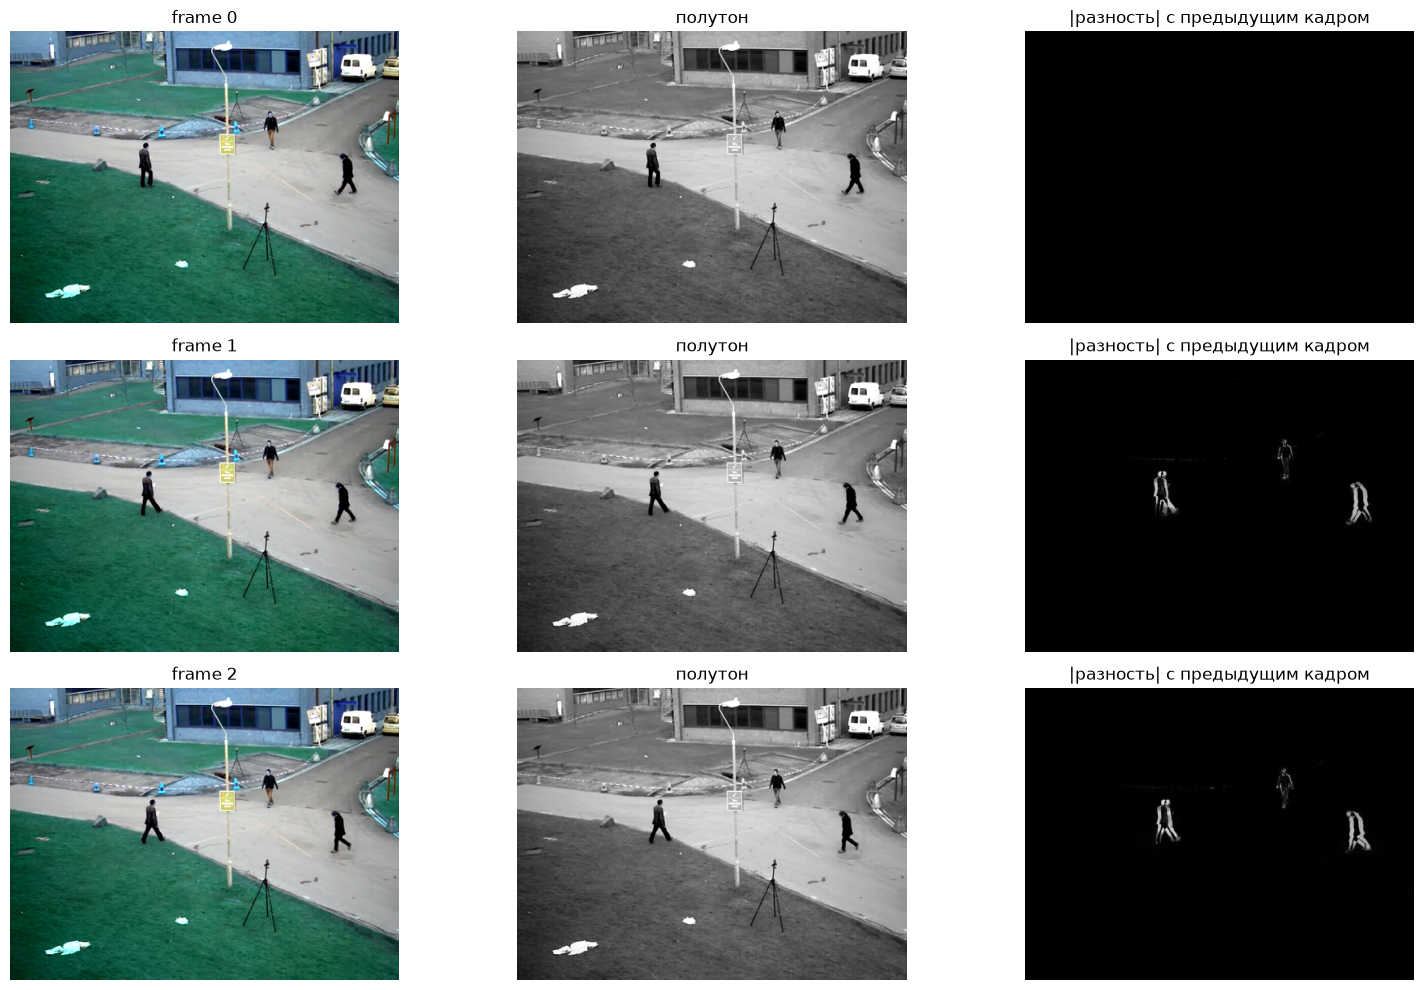

In [57]:
plt.figure(figsize=(16, 10))

for n, (frame, gray_frame, diff_frame) in enumerate(samples):
    plt.subplot(len(samples), 3, 3 * n + 1)
    plt.imshow(frame)
    plt.title(f"frame {n}")
    plt.axis("off")

    plt.subplot(len(samples), 3, 3 * n + 2)
    plt.imshow(gray_frame, "gray", vmin=0, vmax=255)
    plt.title("полутон")
    plt.axis("off")

    plt.subplot(len(samples), 3, 3 * n + 3)
    plt.imshow(diff_frame, "gray", vmin=0, vmax=255)
    plt.title("|разность| с предыдущим кадром")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [58]:
print(f"Gray video : {gray_video_path}")
print(f"Diff video : {diff_video_path}")


Gray video : /Users/vladimirafonchenkov/Projects/comp_vision/lab1/outputs/video_grayscale.mp4
Diff video : /Users/vladimirafonchenkov/Projects/comp_vision/lab1/outputs/video_diff.mp4
